In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("cardio_train.csv", sep=";")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [3]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [4]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64


In [5]:
print("\nDuplicate rows:")
print(df.duplicated().sum())


Duplicate rows:
0


In [6]:
print("\nDescriptive statistics:")
display(df.describe().T)


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


In [7]:
# Keep the original dataset unchanged
clean_df = df.copy()

# Convert age into years
clean_df["age_years"] = clean_df["age"] / 365.25

# Calculate BMI
clean_df["BMI"] = (
    clean_df["weight"] /
    (clean_df["height"] / 100) ** 2
)

# Apply plausible measurement ranges
valid = (
    clean_df["height"].between(120, 220) &
    clean_df["weight"].between(30, 200) &
    clean_df["ap_hi"].between(70, 250) &
    clean_df["ap_lo"].between(40, 150) &
    (clean_df["ap_hi"] > clean_df["ap_lo"])
)

clean_df = clean_df.loc[valid].copy()

# Calculate BMI again using cleaned measurements
clean_df["BMI"] = (
    clean_df["weight"] /
    (clean_df["height"] / 100) ** 2
)

print("Original records:", len(df))
print("Cleaned records:", len(clean_df))
print("Records removed:", len(df) - len(clean_df))
print(
    "Percentage removed:",
    round((1 - len(clean_df) / len(df)) * 100, 2),
    "%"
)

display(clean_df.head())

Original records: 70000
Cleaned records: 68610
Records removed: 1390
Percentage removed: 1.99 %


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,BMI
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0,50.357290,21.967120
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1,55.381246,34.927679
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1,51.627652,23.507805
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1,48.249144,28.710479
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0,47.841205,23.011177


In [8]:
variables = [
    "age_years",
    "BMI",
    "ap_hi",
    "ap_lo",
    "weight",
    "height"
]

summary = clean_df[variables].describe().T

summary = summary.rename(columns={
    "count": "Count",
    "mean": "Mean",
    "std": "Standard Deviation",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum"
})

display(summary.round(2))

,Count,Mean,Standard Deviation,Minimum,Q1,Median,Q3,Maximum
age_years,68610.0,53.29,6.76,29.56,48.34,53.94,58.38,64.92
BMI,68610.0,27.46,5.26,10.73,23.88,26.35,30.12,108.17
ap_hi,68610.0,126.67,16.68,70.00,120.00,120.00,140.00,240.00
ap_lo,68610.0,81.30,9.42,40.00,80.00,80.00,90.00,150.00
weight,68610.0,74.11,14.30,30.00,65.00,72.00,82.00,200.00
height,68610.0,164.41,7.91,120.00,159.00,165.00,170.00,207.00


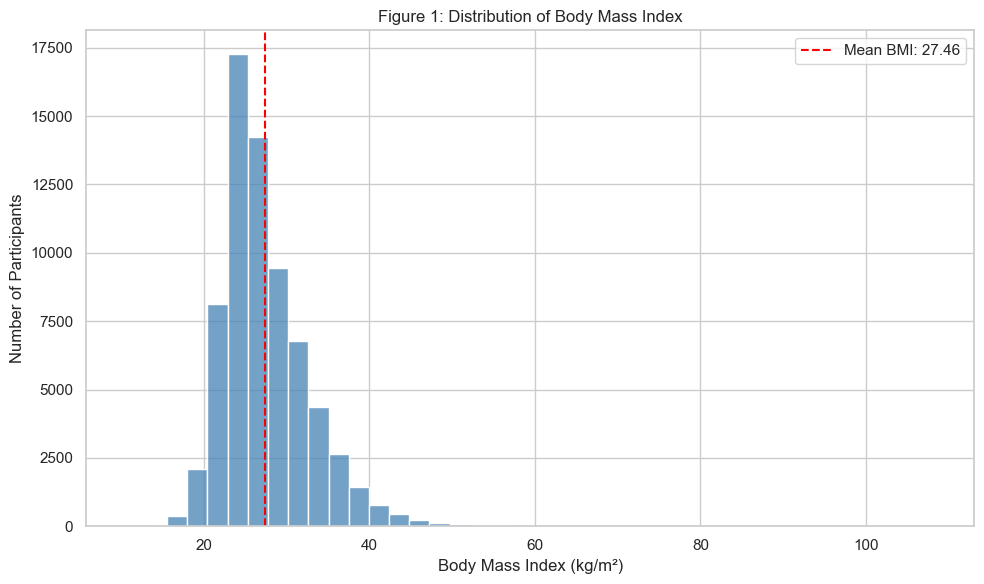

In [9]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=clean_df,
    x="BMI",
    bins=40,
    color="steelblue",
    edgecolor="white"
)

plt.axvline(
    clean_df["BMI"].mean(),
    color="red",
    linestyle="--",
    label=f"Mean BMI: {clean_df['BMI'].mean():.2f}"
)

plt.title("Figure 1: Distribution of Body Mass Index")
plt.xlabel("Body Mass Index (kg/m²)")
plt.ylabel("Number of Participants")
plt.legend()
plt.tight_layout()

plt.savefig("figure1_bmi_histogram.png", dpi=300)
plt.show()

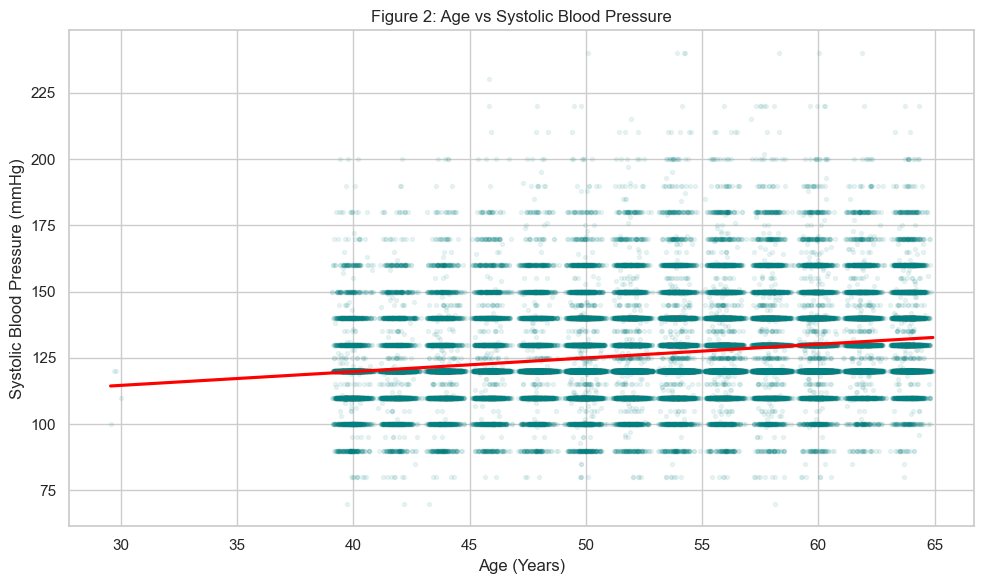

Pearson correlation: 0.209


In [10]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=clean_df,
    x="age_years",
    y="ap_hi",
    scatter_kws={
        "alpha": 0.08,
        "s": 8,
        "color": "teal"
    },
    line_kws={"color": "red"},
    ci=None
)

plt.title(
    "Figure 2: Age vs Systolic Blood Pressure"
)
plt.xlabel("Age (Years)")
plt.ylabel("Systolic Blood Pressure (mmHg)")
plt.tight_layout()

plt.savefig("figure2_age_blood_pressure.png", dpi=300)
plt.show()

correlation = clean_df[
    "age_years"
].corr(clean_df["ap_hi"])

print(
    "Pearson correlation:",
    round(correlation, 3)
)

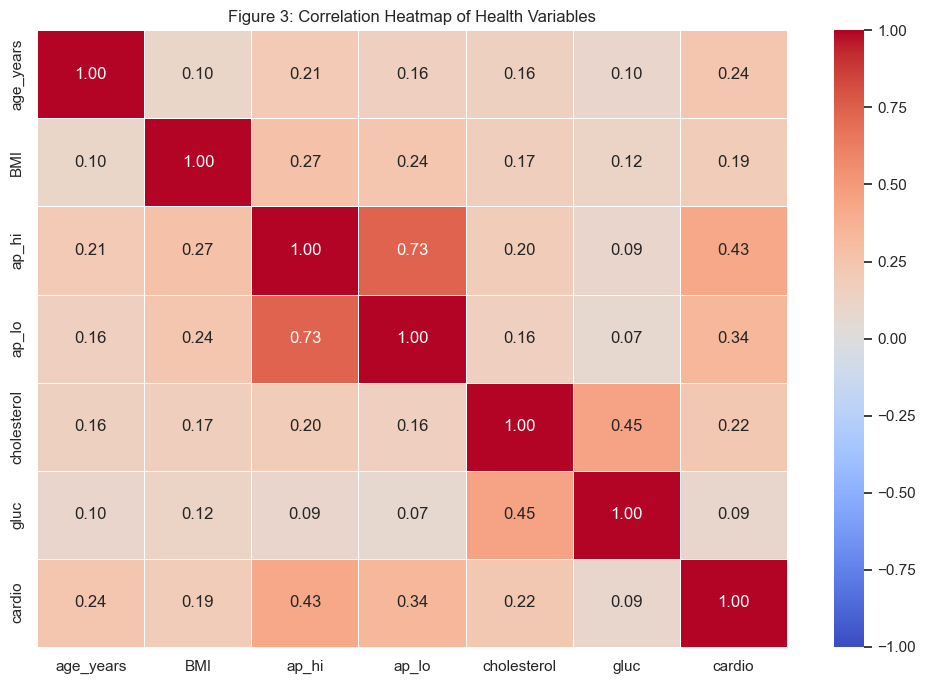

In [11]:
correlation_vars = [
    "age_years",
    "BMI",
    "ap_hi",
    "ap_lo",
    "cholesterol",
    "gluc",
    "cardio"
]

corr_matrix = clean_df[
    correlation_vars
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title(
    "Figure 3: Correlation Heatmap of Health Variables"
)
plt.tight_layout()

plt.savefig("figure3_correlation_heatmap.png", dpi=300)
plt.show()

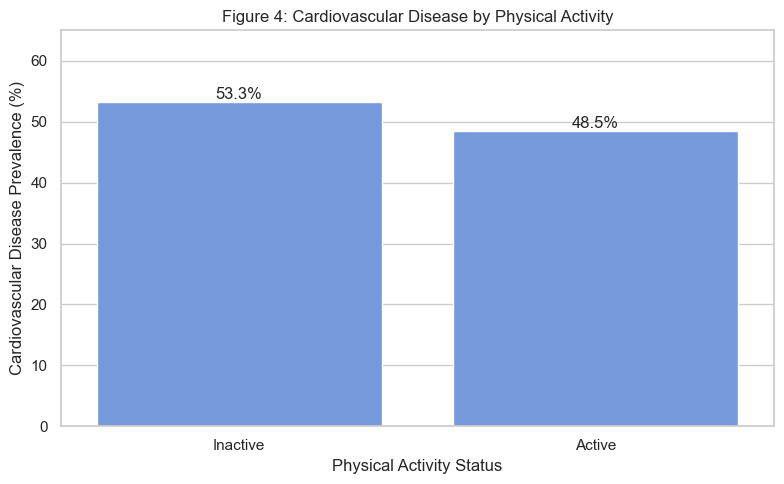

In [12]:
activity_rates = (
    clean_df.groupby("active")["cardio"]
    .mean()
    .mul(100)
    .reindex([0, 1])
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=["Inactive", "Active"],
    y=activity_rates.values,
    color="cornflowerblue"
)

for i, value in enumerate(activity_rates.values):
    ax.text(
        i,
        value + 0.5,
        f"{value:.1f}%",
        ha="center"
    )

plt.title(
    "Figure 4: Cardiovascular Disease by Physical Activity"
)
plt.xlabel("Physical Activity Status")
plt.ylabel("Cardiovascular Disease Prevalence (%)")
plt.ylim(0, 65)
plt.tight_layout()

plt.savefig("figure4_activity_cardio.png", dpi=300)
plt.show()